# 04 - Full evaluation, statistics and publication figures
Runs every strategy on **all three candidate lists**, with 95% cluster-bootstrap CIs (resampling *articles*), the conformal validity check, and exports PNG (300 dpi) + PDF + the plotted data as CSV.

**Outputs:** `csv/strategy_results.csv`, `csv/isobudget_bootstrap.csv`, `csv/rcak_coverage.csv`, `figures/pareto_*`, `figures/isobudget_*`, `figures/coverage_*`, `figures/k_distribution.*`

In [1]:
# ---- Environment setup (works in Colab AND in a local venv / Jupyter) ----
import os, sys, pathlib, subprocess, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu", "sentence-transformers", "python-docx", "psutil"], check=False)
    if not pathlib.Path("adaptive_rag").exists():
        from google.colab import files
        print("Upload rag_adaptive_project.zip (the project archive you downloaded)")
        up = files.upload(); z = [k for k in up if k.endswith(".zip")][0]
        zipfile.ZipFile(z).extractall("."); 
        root = [p for p in pathlib.Path(".").iterdir() if (p / "adaptive_rag").exists()][0]; os.chdir(root)
    try:
        from google.colab import drive; drive.mount("/content/drive")      # results persist on your Drive
        os.environ["RAG_RESULTS_DIR"] = "/content/drive/MyDrive/rag_adaptive_results"
    except Exception as e:
        os.environ["RAG_RESULTS_DIR"] = os.path.abspath("results")
    BACKEND = "st"          # real neural embeddings on Colab (GPU recommended: Runtime > Change runtime type > T4)
else:
    here = pathlib.Path.cwd()
    root = here.parent if here.name == "notebooks" else here
    sys.path.insert(0, str(root)); os.chdir(root)
    os.environ.setdefault("RAG_RESULTS_DIR", str(root / "results_notebooks"))
    BACKEND = "lsa"         # offline CPU baseline (TF-IDF+SVD). Set to "st" if sentence-transformers can download models.
sys.path.insert(0, os.getcwd())
CFG = dict(backend=BACKEND, st_model="sentence-transformers/all-MiniLM-L6-v2", n_queries=int(os.environ.get("RAG_NQ", 10000)), seed=0)
print("backend:", BACKEND, "| results ->", os.environ["RAG_RESULTS_DIR"])


backend: lsa | results -> /home/claude/rag_adaptive_project/results_notebooks


In [2]:
import pandas as pd, numpy as np
from adaptive_rag import experiment as E, plots as P
from adaptive_rag.utils import results_dir
B = E.prepare_cached(CFG)
df, perq, te = E.evaluate(B, return_per_query=True); df.to_csv(results_dir("csv")/"strategy_results.csv", index=False)
cov = E.coverage(B); cov.to_csv(results_dir("csv")/"rcak_coverage.csv", index=False)
iso = pd.concat([E.isobudget(B, s, n_boot=1000) for s in B.lists]); iso.to_csv(results_dir("csv")/"isobudget_bootstrap.csv", index=False)
for s in B.lists:
    P.fig_pareto(df, s, "answer_in_context"); P.fig_pareto(df, s, "hit_rate"); P.fig_coverage(cov, s); P.fig_isobudget(iso, s)
serve = "hybrid_rrf"
P.fig_k_hist({"RCAK alpha=0.10": (perq[(serve,"RCAK (proposed)","alpha=0.1")][0], "RCAK (proposed)"),
              "Adaptive-k buffer=5": (perq[(serve,"adaptive_k_gap","buffer=5")][0], "adaptive_k_gap"),
              "Oracle": (perq[(serve,"oracle_k","min_k")][0], "oracle_k")}, B.rank[serve][te])
print("figures written to", results_dir("figures"))

figures written to /home/claude/rag_adaptive_project/results_notebooks/figures


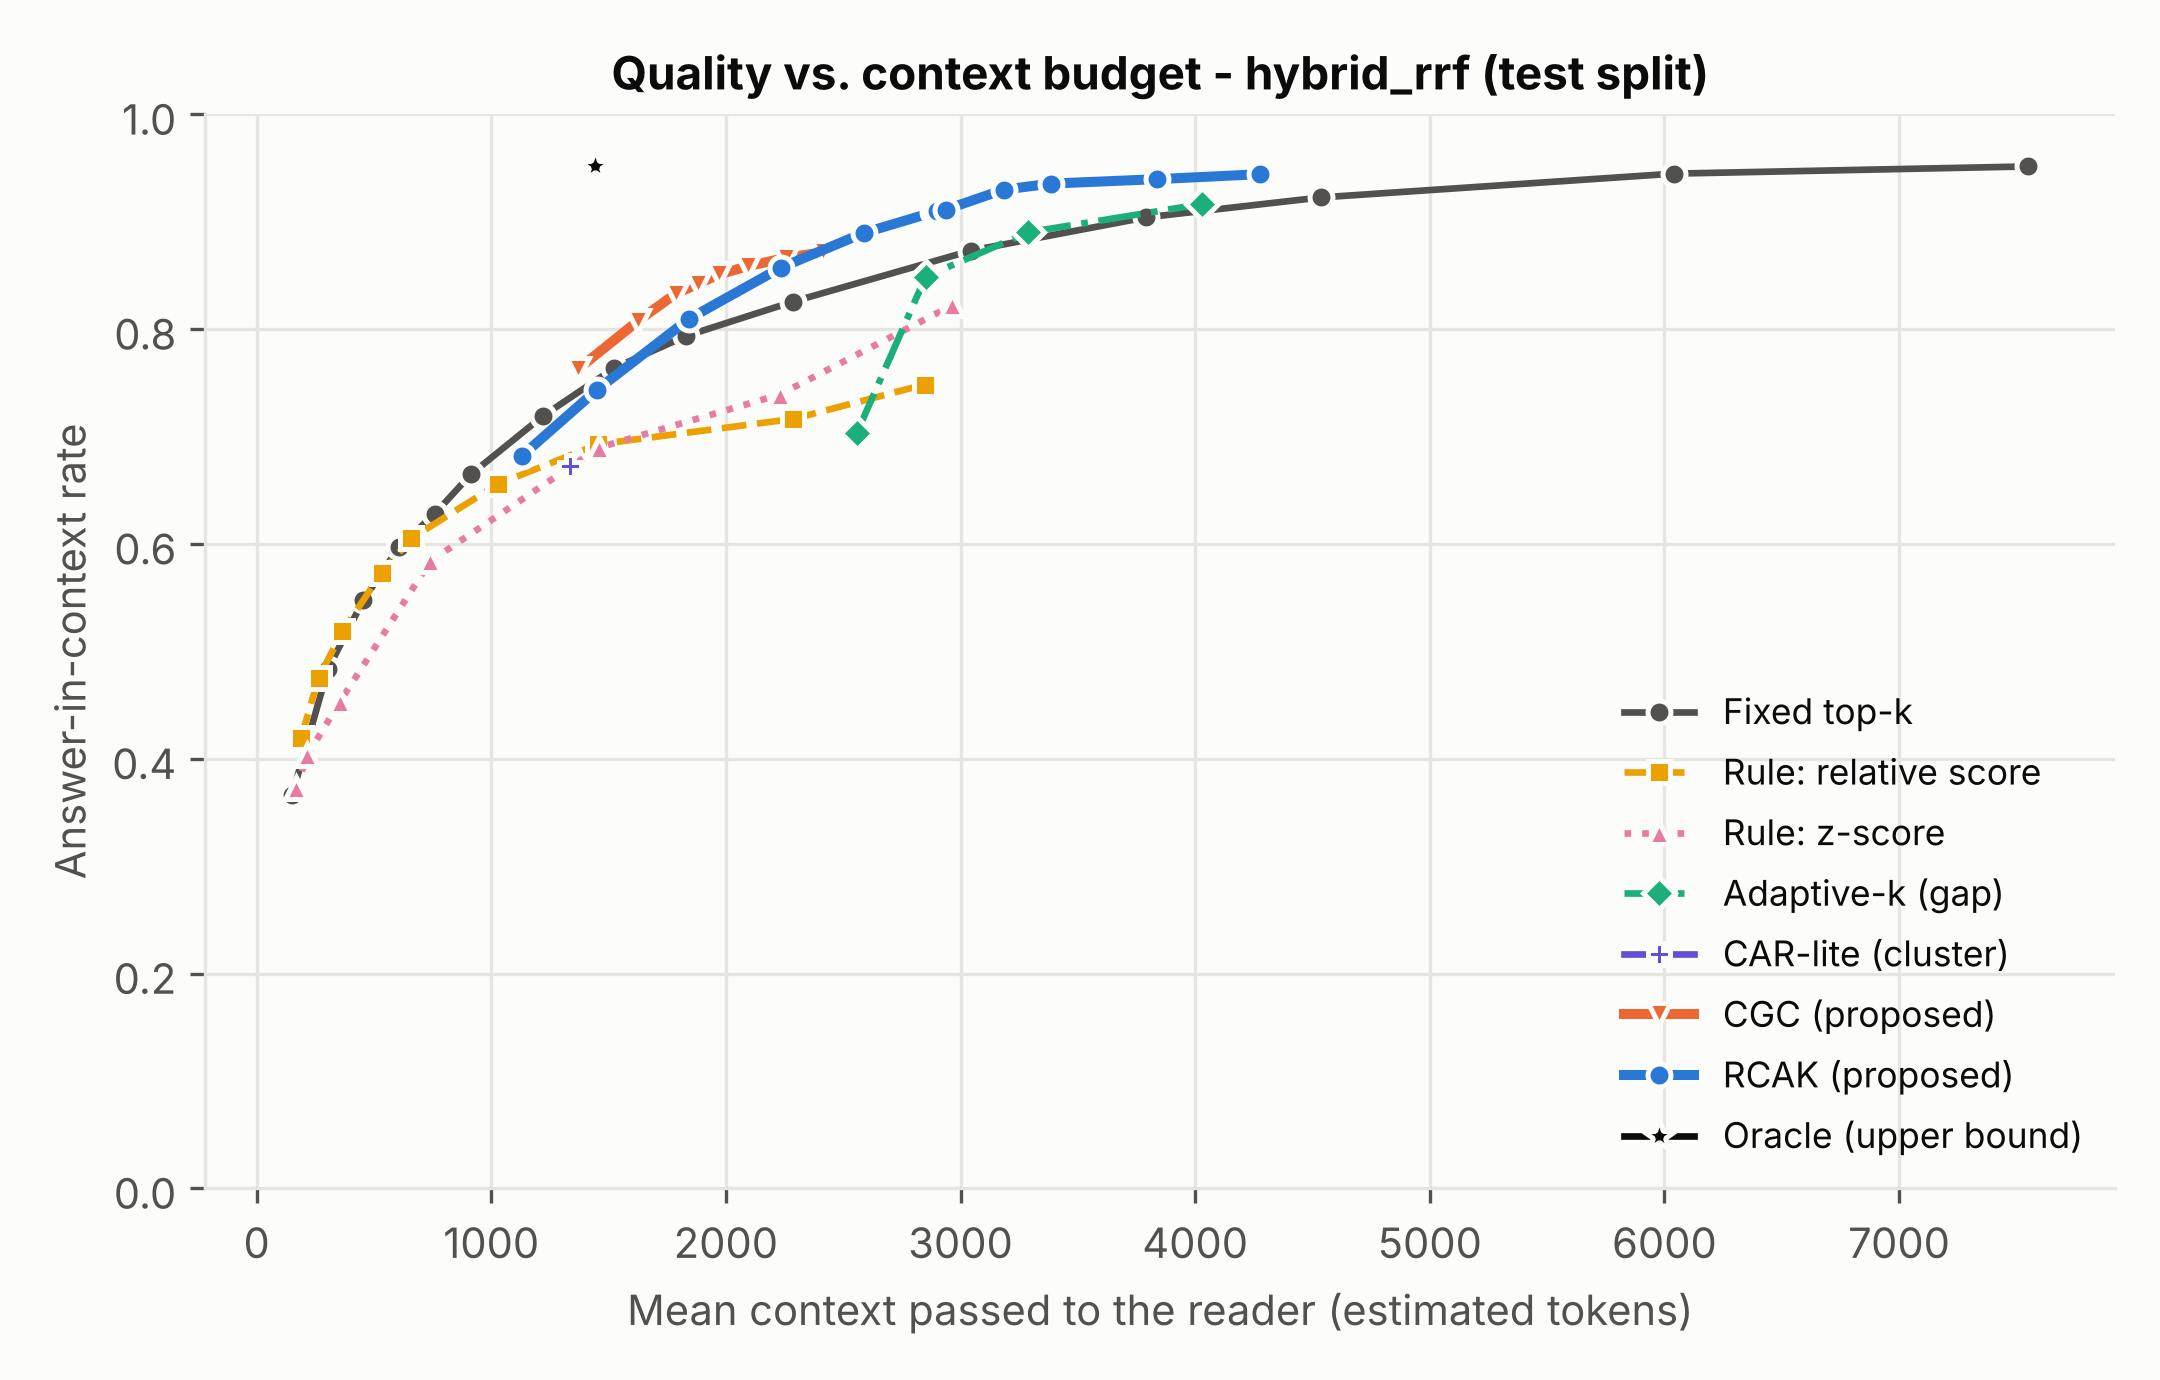

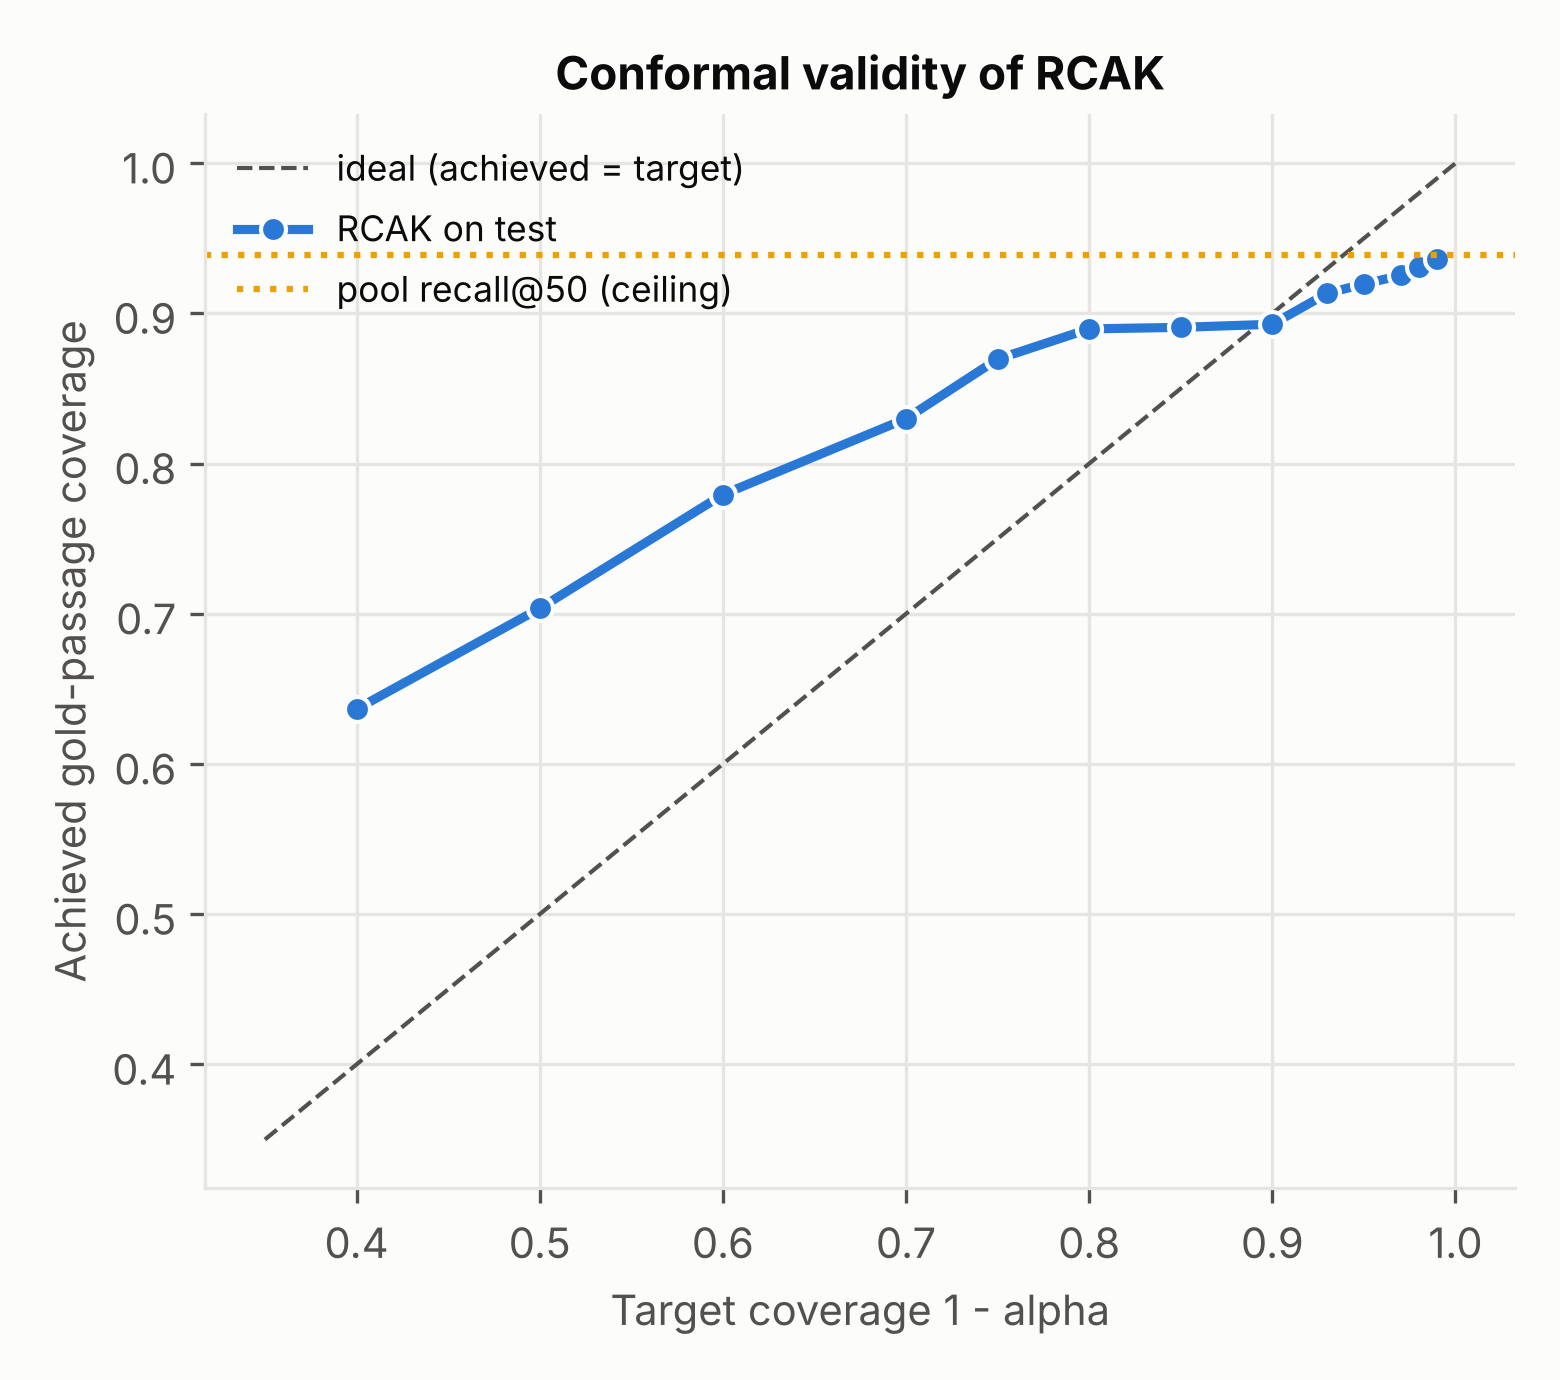

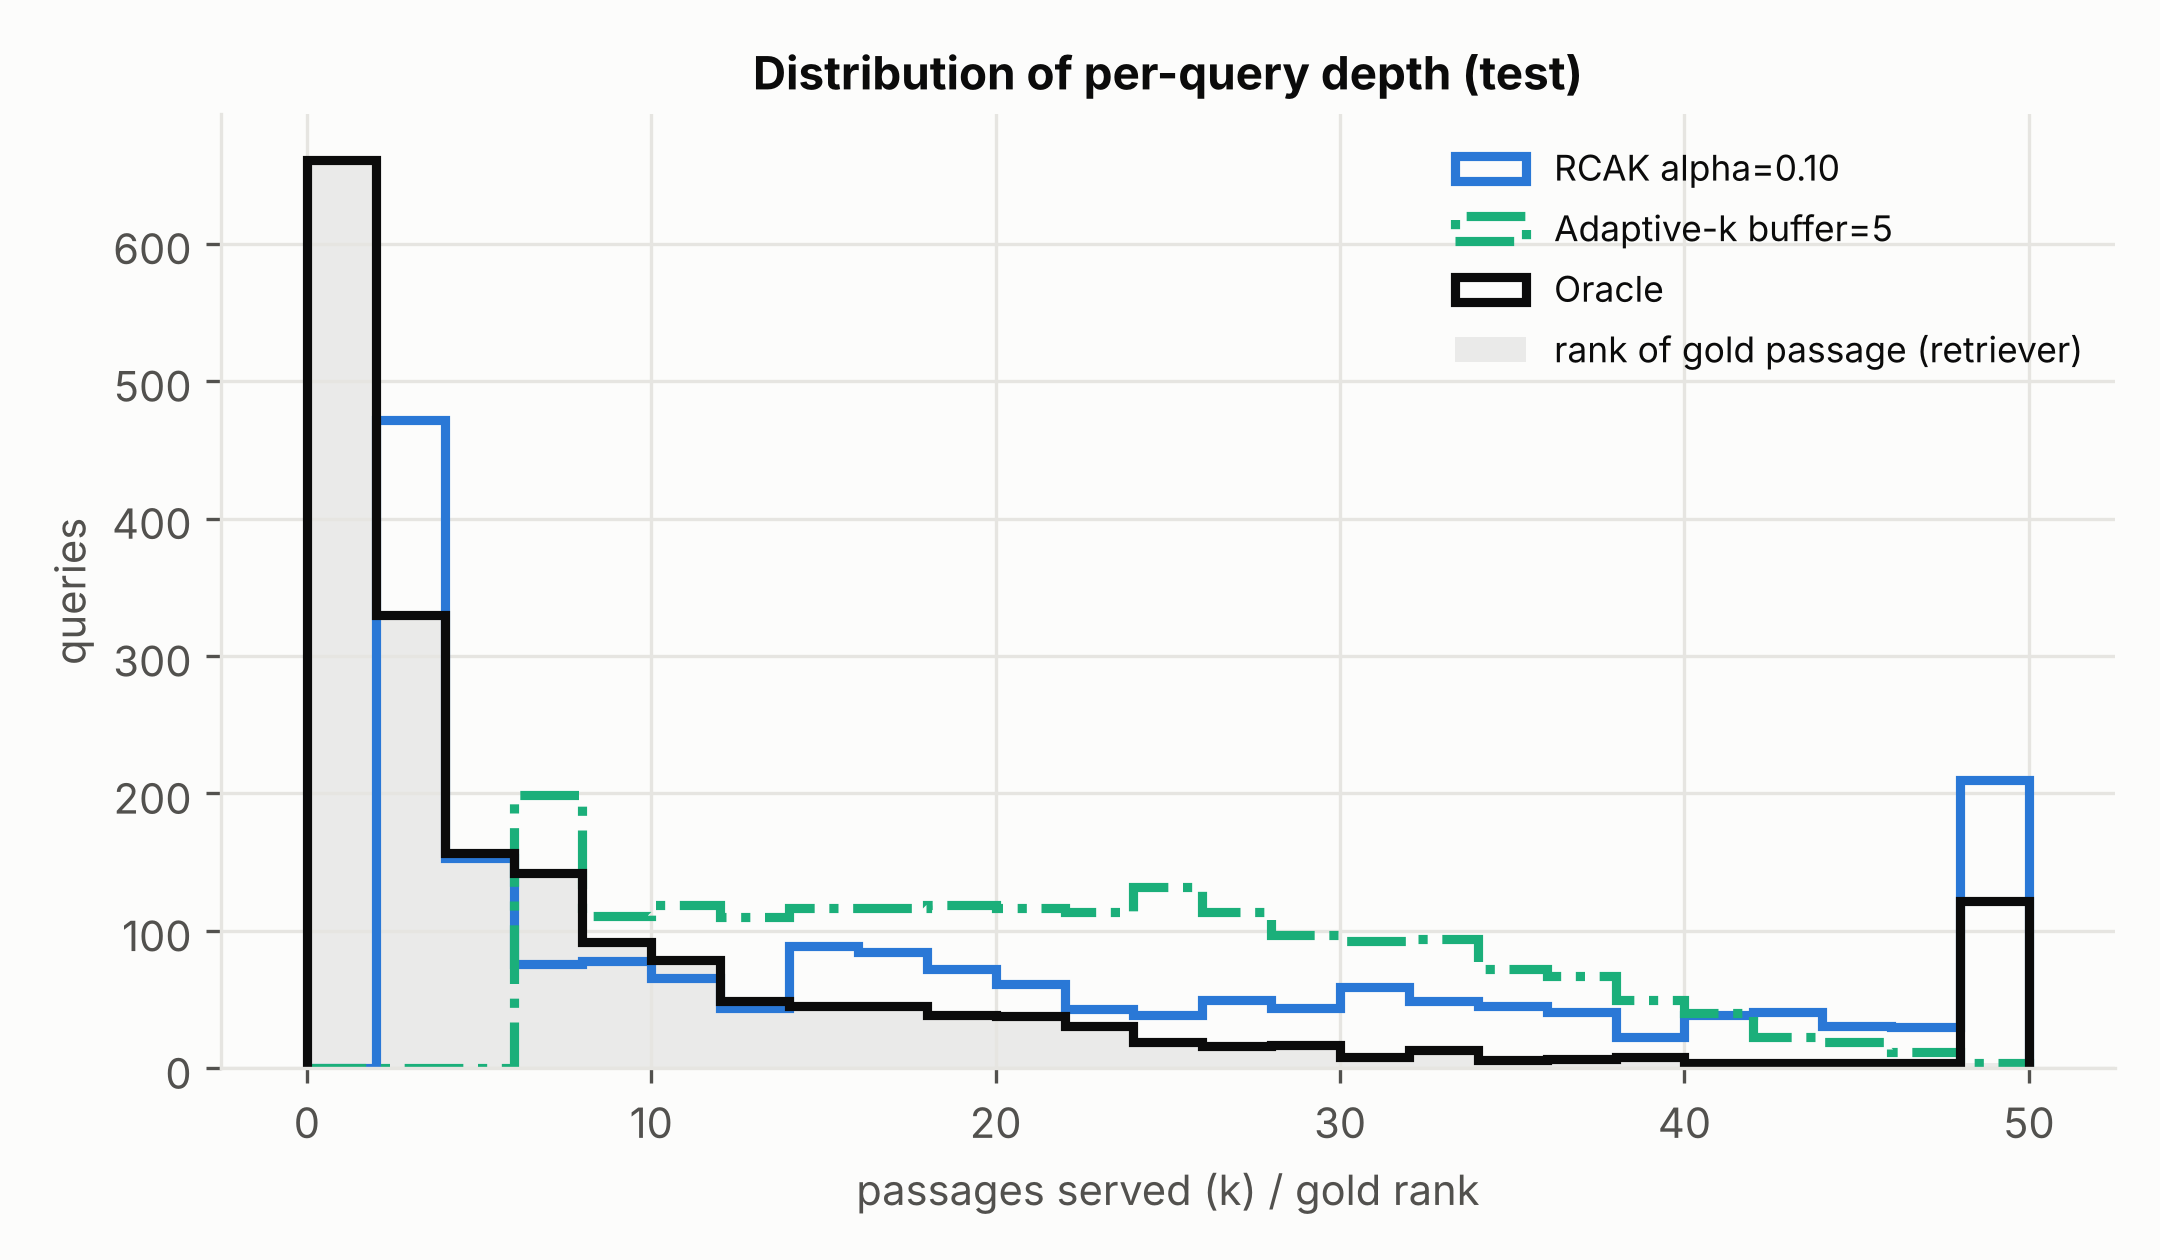

In [3]:
from IPython.display import Image, display
for f in ["pareto_answer_in_context_hybrid_rrf", "coverage_hybrid_rrf", "k_distribution"]:
    display(Image(str(results_dir("figures")/f"{f}.png"), width=620))

**Interpretation guide for the thesis.** (1) Pareto plot: a method is better if its curve is up-and-left of fixed top-k. (2) Iso-budget plot: points right of zero with CIs not crossing zero are significant gains. (3) Coverage plot: achieved coverage should sit on/above the diagonal until it hits the retriever's recall ceiling (pool recall@50).